<a href="https://colab.research.google.com/github/DanielLucero25/CSC349/blob/main/HW4/heart_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSC 349 HW4: Heart Disease

I compare an SVC and a Decision Tree using the UCI Cleveland dataset.

**Status:** Checked locally. Run this notebook in Google Colab before submitting.

[Dataset source](https://archive.ics.uci.edu/dataset/45/heart+disease)

## Task 1: Load the data

I load the UCI Cleveland data into a Pandas DataFrame and add the column names. The original target has values from 0 to 4. I change values above 0 to 1 so the model predicts whether heart disease is present.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, roc_auc_score, roc_curve

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data'

columns = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
           'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

df = pd.read_csv(url, names=columns)
df['target'] = (df['target'] > 0).astype(int)
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Task 2: Check the data

I use head(), info(), and describe() to check the rows, data types, and numerical values. I also count the values in the categorical columns. Some categories use numbers as labels, so they still need to be treated as categories.

In [ ]:
display(df.head())
df.info()
display(df.describe())

for column in ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']:
    print(column)
    print(df[column].value_counts())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        303 non-null    object 
 12  thal      303 non-null    object 
 13  target    303 non-null    int64  
dtypes: float64(11), int64(1), object(2)
memory usage: 33.3+ KB


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.499120
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,1.000000


sex
sex
1.0    206
0.0     97
Name: count, dtype: int64
cp
cp
4.0    144
3.0     86
2.0     50
1.0     23
Name: count, dtype: int64
fbs
fbs
0.0    258
1.0     45
Name: count, dtype: int64
restecg
restecg
0.0    151
2.0    148
1.0      4
Name: count, dtype: int64
exang
exang
0.0    204
1.0     99
Name: count, dtype: int64
slope
slope
1.0    142
2.0    140
3.0     21
Name: count, dtype: int64
ca
ca
0.0    176
1.0     65
2.0     38
3.0     20
?        4
Name: count, dtype: int64
thal
thal
3.0    166
7.0    117
6.0     18
?        2
Name: count, dtype: int64


## Task 3: Handle missing values

I check for normal missing values and question marks. I replace question marks and blank spaces with NaN, then convert the columns to numbers. In the next task, SimpleImputer will fill numerical values with the median and categories with the most common value. It only learns these values from the training data.

In [ ]:
print('Missing values:')
print(df.isnull().sum())

print('Question marks:')
print((df == '?').sum())

df = df.replace('?', np.nan)
df = df.replace(r'^\s*$', np.nan, regex=True)
df = df.apply(pd.to_numeric)

print('Missing values after cleaning:')
print(df.isnull().sum())

X = df.drop(columns=['target'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64
Question marks:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64
Missing values after cleaning:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


## Task 4: Build the preprocessing pipeline

I separate numerical and categorical features. The numerical pipeline fills missing values and scales the data. The categorical pipeline fills missing values and uses one-hot encoding. ColumnTransformer combines both steps. Each model uses this preprocessing inside its pipeline.

In [ ]:
numerical_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
categorical_features = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'trestbps', 'chol', 'thalach',
                                  'oldpeak']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['sex', 'cp', 'fbs', 'restecg', 'exang',
                                  'slope', 'ca', 'thal'])])

## Task 5: Train and evaluate the SVC

I train an SVC with an RBF kernel and probability=True. I use the test data to make predictions. The confusion matrix and classification report show correct predictions and mistakes. The ROC curve and AUC show how well the model separates patients with and without disease.

              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

SVC ROC-AUC: 0.9642857142857143


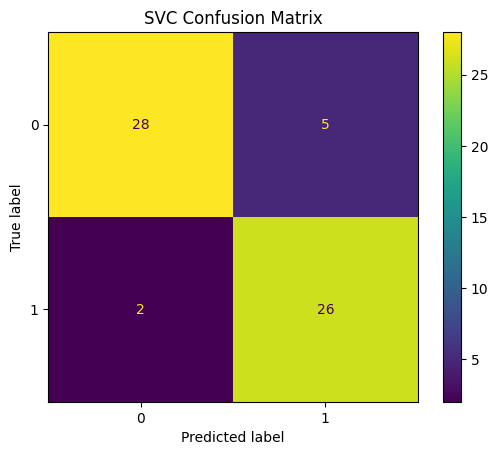

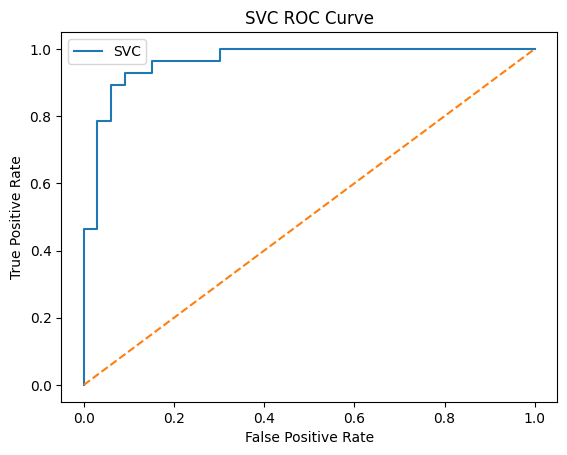

In [ ]:
svc_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', SVC(kernel='rbf', probability=True, random_state=42))
])

svc_pipeline.fit(X_train, y_train)

svc_pred = svc_pipeline.predict(X_test)
svc_prob = svc_pipeline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, svc_pred))
print('SVC ROC-AUC:', roc_auc_score(y_test, svc_prob))

ConfusionMatrixDisplay.from_predictions(y_test, svc_pred)
plt.title('SVC Confusion Matrix')
plt.show()

fpr, tpr, thresholds = roc_curve(y_test, svc_prob)
plt.plot(fpr, tpr, label='SVC')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('SVC ROC Curve')
plt.legend()
plt.show()

## Task 6: Train and evaluate the Decision Tree

I train a Decision Tree with the same training data and preprocessing. I check it with the same metrics as the SVC so I can compare them. I also print training and test accuracy to check whether the tree may be overfitting.

              precision    recall  f1-score   support

           0       0.81      0.67      0.73        33
           1       0.68      0.82      0.74        28

    accuracy                           0.74        61
   macro avg       0.75      0.74      0.74        61
weighted avg       0.75      0.74      0.74        61

Tree ROC-AUC: 0.7440476190476191
Training accuracy: 1.0
Test accuracy: 0.7377049180327869


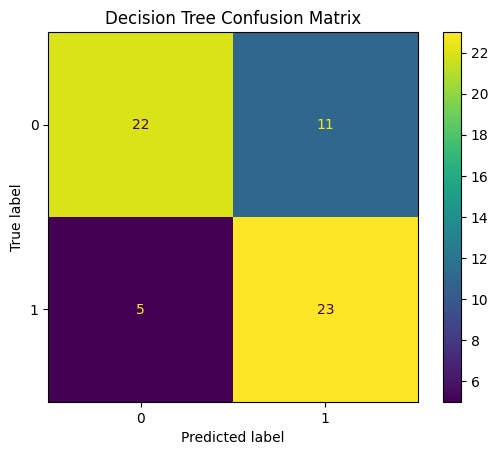

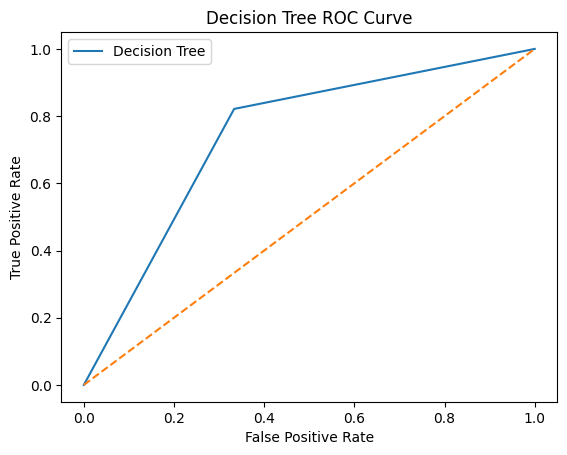

In [ ]:
tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

tree_pipeline.fit(X_train, y_train)

tree_pred = tree_pipeline.predict(X_test)
tree_prob = tree_pipeline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, tree_pred))
print('Tree ROC-AUC:', roc_auc_score(y_test, tree_prob))
print('Training accuracy:', tree_pipeline.score(X_train, y_train))
print('Test accuracy:', tree_pipeline.score(X_test, y_test))

ConfusionMatrixDisplay.from_predictions(y_test, tree_pred)
plt.title('Decision Tree Confusion Matrix')
plt.show()

fpr, tpr, thresholds = roc_curve(y_test, tree_prob)
plt.plot(fpr, tpr, label='Decision Tree')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Decision Tree ROC Curve')
plt.legend()
plt.show()

## Task 7: Tune the SVC

I use GridSearchCV to try different C and gamma values. It uses five folds of the training data to choose the best average ROC-AUC. Preprocessing is also fitted inside each fold. I then check the selected model on the test data.

In [ ]:
param_grid = {
    'classifier__C': [0.1, 1, 10, 100],
    'classifier__gamma': ['scale', 0.001, 0.01, 0.1, 1]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    svc_pipeline, param_grid, cv=cv, scoring='roc_auc'
)

grid_search.fit(X_train, y_train)

print('Best parameters:', grid_search.best_params_)
print('Best cross-validation ROC-AUC:', grid_search.best_score_)

tuned_pred = grid_search.predict(X_test)
tuned_prob = grid_search.predict_proba(X_test)[:, 1]

print(classification_report(y_test, tuned_pred))
print('Tuned SVC ROC-AUC:', roc_auc_score(y_test, tuned_prob))

Best parameters: {'classifier__C': 100, 'classifier__gamma': 0.001}
Best cross-validation ROC-AUC: 0.9026992331340157
              precision    recall  f1-score   support

           0       0.90      0.82      0.86        33
           1       0.81      0.89      0.85        28

    accuracy                           0.85        61
   macro avg       0.85      0.86      0.85        61
weighted avg       0.86      0.85      0.85        61

Tuned SVC ROC-AUC: 0.948051948051948


## Task 8: Check important features

I get the feature names and importance scores from the fitted Decision Tree. I put them in a table and show the ten largest scores in a chart. Encoded names show individual categories. A higher score means the tree used that feature more, but it does not show what causes heart disease.

,Feature,Importance
25,cat__thal_3.0,0.292921
10,cat__cp_4.0,0.119427
2,num__chol,0.110055
4,num__oldpeak,0.107935
21,cat__ca_0.0,0.097622
0,num__age,0.096128
5,cat__sex_0.0,0.033909
1,num__trestbps,0.027639
9,cat__cp_3.0,0.019416
3,num__thalach,0.018673


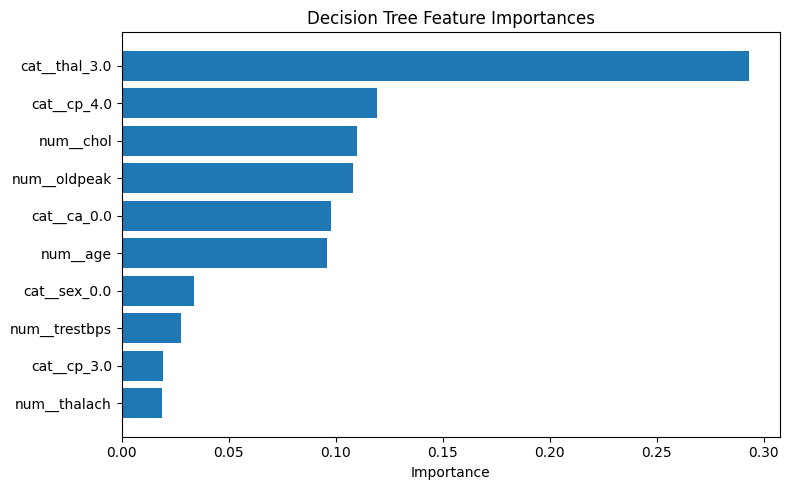

In [ ]:
feature_names = tree_pipeline.named_steps['preprocessor'].get_feature_names_out()
importances = tree_pipeline.named_steps['classifier'].feature_importances_

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

importance_df = importance_df.sort_values('Importance', ascending=False)
display(importance_df.head(10))

plt.figure(figsize=(8, 5))
plt.barh(importance_df['Feature'].head(10), importance_df['Importance'].head(10))
plt.gca().invert_yaxis()
plt.xlabel('Importance')
plt.title('Decision Tree Feature Importances')
plt.tight_layout()
plt.show()